# EXP-005 — Random Forest mặc định
Người thực hiện:   Mai  
Ngày chạy: 16/11/2026  
Trạng thái: cần chạy lại

## Mục tiêu và giả thuyết

Thí nghiệm sử dụng Random Forest (RF) để đánh giá khả năng nhận diện stress trên người chưa xuất hiện trong tập huấn luyện. Giả thuyết đặt ra là RF đạt Macro-F1 và Balanced Accuracy cao hơn Dummy vì RF có thể học từ 68 đặc trưng sinh lý. Kết quả cũng giúp đánh giá mức độ phù hợp của RF cho demo CSV.

## Dữ liệu và cách đánh giá

Dùng physiological68 gồm 6.189 cửa sổ, 68 đặc trưng và 15 người. Mỗi fold LOSO giữ một người để test và dùng 14 người còn lại để train. Chạy riêng bài toán Stress/Non-stress và bài toán Baseline/Stress/Amusement.

RF dùng `RandomForestClassifier(random_state=42, n_jobs=1)`. Median imputer được fit trong từng fold train. Giao thức này dùng tham số mặc định của RF, không tuning, cân bằng lớp hay chọn đặc trưng. SHA-256 và đường dẫn schema nằm trong `config.yaml`.

In [6]:
from pathlib import Path
import json

import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/01_baselines/EXP-005_RF"
config = yaml.safe_load((experiment / "config.yaml").read_text(encoding="utf-8"))
output = repo / config["output_dir"]
data = pd.read_csv(repo / config["features"], usecols=["subject_id", "label_original"])
print(f"{len(data)} cửa sổ, {data['subject_id'].nunique()} người")
display(data["label_original"].map({1: "Baseline", 2: "Stress", 3: "Amusement"}).value_counts())


6189 cửa sổ, 15 người


label_original
Baseline     3370
Stress       1848
Amusement     971
Name: count, dtype: int64

## Thiết lập thực nghiệm

Thí nghiệm sử dụng runner G3 với cấu hình `config.yaml`, seed 42 và thư mục kết quả riêng `outputs/exp005_rf_full`. Cả hai bài toán dùng cùng cách chia dữ liệu. Tham số RF được giữ cố định qua các fold.

In [7]:
import subprocess

RUN_TRAIN = False
command = [
    str(repo / ".venv-g1/Scripts/python.exe"),
    "-X", "utf8", "scripts/run_g3_baselines.py",
    "--config", str(experiment / "config.yaml"),
    "--resume",
]
print((experiment / "config.yaml").read_text(encoding="utf-8"))

if RUN_TRAIN:
    subprocess.run(command, cwd=repo, check=True)


protocol: g3_defaults_physiological68_v1
features: data/features/g2_physiological68_group15_20261107/all_subjects.csv
schema: data/features/g2_physiological68_group15_20261107/feature_schema.json
feature_version: physiological_68_v1
feature_sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
output_dir: outputs/exp005_rf_full
source_paths:
- src/wesad/data.py
- src/wesad/evaluation.py
- src/wesad/models.py
- src/wesad/utils.py
- src/wesad/g3.py
- scripts/run_g3_baselines.py
- scripts/merge_g3_predictions.py
source_hash_normalization: LF
expected_subjects:
- S2
- S3
- S4
- S5
- S6
- S7
- S8
- S9
- S10
- S11
- S13
- S14
- S15
- S16
- S17
models:
- rf
tasks:
- multiclass
- binary
seed: 42
sensor_set: combined_physiological68
normalization: global_train
balance: false
nested: false
zero_division: 0
missing_train_class: error
missing_test_class: fixed_labels_for_macro_f1_observed_classes_for_balanced_accuracy
model_params:
  rf:
    random_state: 42
    n_jobs: 1



## Kết quả theo người tham gia

Macro-F1 là trung bình F1 của các lớp và Balanced Accuracy là trung bình recall của các lớp. Hai chỉ số được tính riêng cho từng người trong tập test. Kết quả của mỗi bài toán được tổng hợp bằng trung bình và độ lệch chuẩn mẫu qua 15 người.

Bảng `results.csv` lưu 30 dòng RF từ `reports/g3_group/metrics_by_subject.csv` (kết quả lịch sử G3). Điểm từ lượt chạy lại đã xác minh được xuất riêng vào `results_rerun.csv`.

In [8]:
g3_source = repo / "reports/g3_group/metrics_by_subject.csv"
g3 = pd.read_csv(g3_source)
verification_file = output / "verification.json"
has_rerun = verification_file.is_file()

if has_rerun:
    verification = json.loads(verification_file.read_text(encoding="utf-8"))
    assert verification["status"] == "passed"
    assert verification["scope"] == "main" and verification["models"] == ["rf"]
    assert verification["data_sha256"] == config["feature_sha256"]
    assert verification["n_folds"] == 30 and verification["n_predictions"] == 12378
    rf_source = output / "verified_metrics_by_subject.csv"
    results = pd.read_csv(rf_source)
    run_info = json.loads((output / "config.json").read_text(encoding="utf-8"))
    print("Trạng thái: rerun")
    print("Commit nguồn:", run_info.get("git_commit") or "Chưa xác minh")
    print("Dấu vân tay mã nguồn:", verification["code_sha256"])
    print("Môi trường:", (output / "environment.json").relative_to(repo))
else:
    rf_source = g3_source
    results = g3.loc[g3["model"].eq("rf")].copy()
    print("Trạng thái: historical (phân tích kết quả G3)")
    print("Nguồn hồ sơ: docs/G3_TONG_HOP.md")

keys = ["task", "subject_id"]
assert len(results) == 30 and not results.duplicated(keys).any()
assert set(results["model"]) == {"rf"}
assert set(results["task"]) == {"binary", "multiclass"}
assert results.groupby("task")["subject_id"].apply(
    lambda ids: set(ids) == set(config["expected_subjects"])
).all()

if has_rerun:
    results.to_csv(experiment / "results_rerun.csv", index=False)

print("Nguồn điểm RF:", rf_source.relative_to(repo))
metrics = ["macro_f1", "balanced_accuracy"]
display(results[keys + metrics].sort_values(keys).round(4))
display(results.groupby("task")[metrics].agg(["mean", "std"]).round(4))


Trạng thái: historical (phân tích kết quả G3)
Nguồn hồ sơ: docs/G3_TONG_HOP.md
Nguồn điểm RF: reports\g3_group\metrics_by_subject.csv


,task,subject_id,macro_f1,balanced_accuracy
90,binary,S10,0.5017,0.6409
91,binary,S11,0.9832,0.9897
92,binary,S13,0.6991,0.7884
93,binary,S14,0.9855,0.9802
94,binary,S15,0.6856,0.6667
95,binary,S16,1.0000,1.0000
96,binary,S17,0.9028,0.8840
97,binary,S2,0.9177,0.8947
98,binary,S3,0.9366,0.9153
99,binary,S4,1.0000,1.0000


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8735  0.1440            0.8865  0.1143
multiclass   0.6480  0.1297            0.6700  0.1204

## Đối chiếu với các mô hình cơ sở

Phần này so sánh RF với Dummy, LR, KNN, SVM và MLP trên cùng 15 người và tách riêng hai bài toán. Điểm RF lấy từ nguồn ghi ở phần kết quả. Điểm của năm mô hình đối chiếu lấy từ bảng G3. Phần chênh lệch theo từng người dùng Dummy làm mốc vì Dummy luôn dự đoán lớp phổ biến nhất trong tập train.

macro_f1  balanced_accuracy
task       model                               
binary     Dummy      0.4123             0.5000
           KNN        0.7258             0.7541
           LR         0.8103             0.8304
           MLP        0.7986             0.8225
           RF (G3)    0.8735             0.8865
           SVM        0.8424             0.8663
multiclass Dummy      0.2350             0.3333
           KNN        0.5555             0.5753
           LR         0.5894             0.6315
           MLP        0.6462             0.6815
           RF (G3)    0.6480             0.6700
           SVM        0.6177             0.6595

,macro_f1_rf,macro_f1_dummy,macro_f1_delta,balanced_accuracy_rf,balanced_accuracy_dummy,balanced_accuracy_delta
task,,,,,,
binary,0.8735,0.4123,0.4612,0.8865,0.5000,0.3865
multiclass,0.6480,0.2350,0.4129,0.6700,0.3333,0.3367


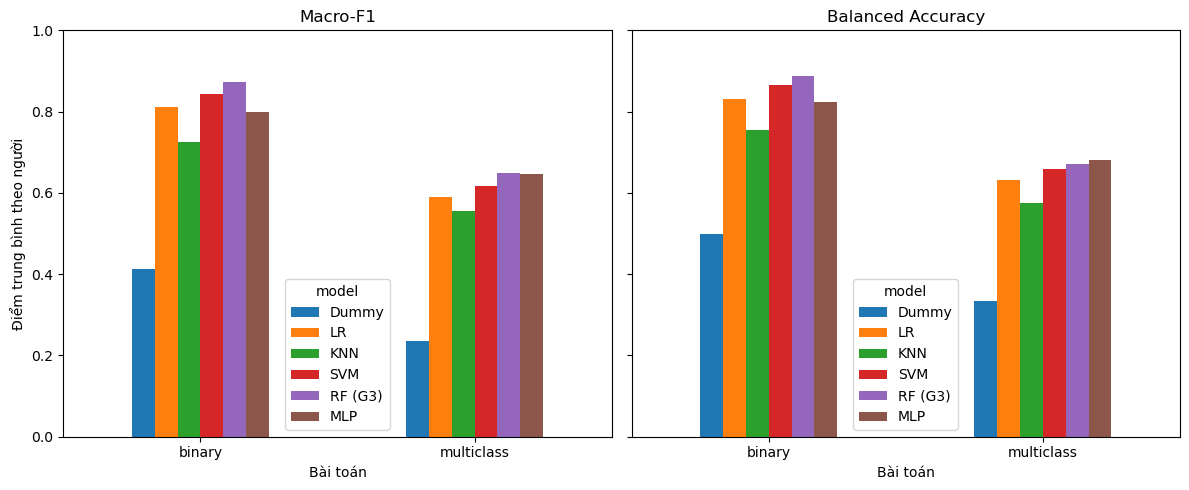

In [9]:
import matplotlib.pyplot as plt

dummy = g3.loc[g3["model"].eq("dummy")]
rf_label = "RF (lượt chạy lại)" if has_rerun else "RF (G3)"
model_labels = {"dummy": "Dummy", "lr": "LR", "knn": "KNN", "svm": "SVM", "rf": rf_label, "mlp": "MLP"}
baseline_rows = pd.concat([g3.loc[g3["model"].ne("rf")], results], ignore_index=True)
model_scores = baseline_rows.groupby(["task", "model"])[metrics].mean()
display(model_scores.rename(index=model_labels, level="model").round(4))
keys = ["task", "subject_id"]
paired = results.merge(dummy[keys + metrics], on=keys, suffixes=("_rf", "_dummy"), validate="one_to_one")
assert len(paired) == 30

for metric in metrics:
    paired[f"{metric}_delta"] = paired[f"{metric}_rf"] - paired[f"{metric}_dummy"]

columns = [f"{metric}_{suffix}" for metric in metrics for suffix in ("rf", "dummy", "delta")]
comparison = paired.groupby("task")[columns].mean()
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric, title in zip(axes, metrics, ["Macro-F1", "Balanced Accuracy"]):
    scores = model_scores[metric].unstack("model").reindex(columns=list(model_labels))
    scores.rename(columns=model_labels).plot.bar(ax=ax, rot=0, title=title)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Bài toán")
axes[0].set_ylabel("Điểm trung bình theo người")
fig.tight_layout()
if has_rerun:
    figures = experiment / "figures"
    figures.mkdir(exist_ok=True)
    fig.savefig(figures / "rf_vs_baselines.png", dpi=150)
plt.show()


## Nhận xét và kết luận

Trong kết quả lịch sử G3, RF đạt Macro-F1 **0,8735** và Balanced Accuracy **0,8865** ở bài toán nhị phân. Với ba lớp, hai điểm lần lượt là **0,6480** và **0,6700**. RF vượt Dummy trên cả hai chỉ số ở cả hai bài toán.

RF dẫn đầu các mô hình cơ sở G3 ở cả hai chỉ số trong bài toán nhị phân. Với ba lớp, RF có Macro-F1 cao nhất, còn MLP có Balanced Accuracy cao hơn RF (0,6815 so với 0,6700). Điểm trung bình cho thấy RF là ứng viên hợp lý cho demo nhị phân trên dữ liệu physiological68. Chênh lệch giữa các mô hình ở bài toán ba lớp cần được xem cùng độ biến thiên giữa người tham gia. Thí nghiệm này chưa đo độ trễ suy luận.

Kết quả G3 là mốc tham chiếu lịch sử. Cell dưới tổng hợp kết quả từ nguồn RF đang được phân tích và cho biết số người có Macro-F1 cải thiện so với Dummy.

In [10]:
from IPython.display import Markdown

task_names = {"binary": "Nhị phân", "multiclass": "Ba lớp"}
source_name = "lượt chạy lại đã xác minh" if has_rerun else "kết quả lịch sử G3"
lines = [f"**Kết quả từ {source_name}**"]
for task, folds in paired.groupby("task"):
    scores = comparison.loc[task]
    improved = folds["macro_f1_delta"].gt(0).sum()
    weakest = folds.loc[folds["macro_f1_rf"].idxmin()]
    lines.append(
        f"- **{task_names[task]}** — Macro-F1 {scores['macro_f1_rf']:.4f} "
        f"(chênh lệch so với Dummy {scores['macro_f1_delta']:+.4f}), "
        f"Balanced Accuracy {scores['balanced_accuracy_rf']:.4f} "
        f"(chênh lệch {scores['balanced_accuracy_delta']:+.4f}). "
        f"Macro-F1 cao hơn Dummy ở {improved}/{len(folds)} người. "
        f"Fold có Macro-F1 RF thấp nhất là {weakest['subject_id']} "
        f"({weakest['macro_f1_rf']:.4f})."
    )
display(Markdown("\n".join(lines)))


**Kết quả từ kết quả lịch sử G3**
- **Nhị phân** — Macro-F1 0.8735 (chênh lệch so với Dummy +0.4612), Balanced Accuracy 0.8865 (chênh lệch +0.3865). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.5017).
- **Ba lớp** — Macro-F1 0.6480 (chênh lệch so với Dummy +0.4129), Balanced Accuracy 0.6700 (chênh lệch +0.3367). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.3649).